# 03 · Cribado de análisis: qué vale la pena modelar a fondo

Con la base del laboratorio se pueden plantear muchos análisis (prever volúmenes, anticipar
resultados, agrupar clientes), y estudiarlos todos a fondo no es viable. En esta etapa se los somete
a la misma prueba rápida y se decide, con una regla fijada de antemano, cuáles pasan al modelado
detallado de las etapas 04 a 06.

← Anterior: [02 · Exploración](02_exploracion.ipynb) &nbsp;·&nbsp; [Notebook completo](Proyecto_Final.ipynb) &nbsp;·&nbsp; Siguiente: [04 · Regresión](04_regresion.ipynb) →

## Código del proyecto

La celda siguiente recrea el paquete `proyecto/` dentro de la sesión, de forma que el notebook funciona en Google Colab sin clonar ningún repositorio: basta con ejecutarla una vez (*Entorno de ejecución → Ejecutar todas*). En una copia local del repositorio no reemplaza ningún archivo. La sección puede plegarse desde su título. Trae también los guiones de las etapas anteriores: si sus resultados no están en la sesión, la etapa los vuelve a calcular en silencio antes de empezar.

In [ ]:
# Código del proyecto. Esta celda recrea en el directorio de trabajo:
#   - el paquete `proyecto/` (49 módulos) y `configuracion/mapeo_columnas.json`;
#   - los guiones de las 2 etapas previas (se reconstruyen si faltan);
# para que el notebook funcione en Google Colab sin clonar el repositorio. Todo viaja
# al final de la celda como un .tar.xz en base64 (62 archivos, 179 kB).
# Antes de extraer se comprueba su huella SHA-256. Un archivo que ya existe con el
# mismo contenido no se toca, y uno que existe con otro contenido (una copia local
# del repositorio con cambios, por ejemplo) se conserva y se avisa; para
# reemplazarlo hay que poner SOBRESCRIBIR = True.
import base64
import hashlib
import importlib
import io
import os
import sys
import tarfile
from pathlib import Path

SOBRESCRIBIR = False


def recrear_proyecto(huella, codificado):
    datos = base64.b64decode(codificado)
    if hashlib.sha256(datos).hexdigest() != huella:
        raise ValueError("El código embebido está dañado: su SHA-256 no coincide.")
    escritos, iguales, conservados = 0, 0, []
    with tarfile.open(fileobj=io.BytesIO(datos), mode="r:xz") as archivo:
        for miembro in archivo.getmembers():
            nombre = miembro.name
            if Path(nombre).is_absolute() or ".." in Path(nombre).parts:
                raise ValueError(f"Ruta no permitida en el archivo: {nombre}")
            contenido, destino = archivo.extractfile(miembro).read(), Path(nombre)
            if destino.exists() and destino.read_bytes() == contenido:
                iguales += 1
            elif destino.exists() and not SOBRESCRIBIR:
                conservados.append(nombre)
            else:
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(contenido)
                escritos += 1
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    importlib.invalidate_caches()
    print(f"Código del proyecto: {escritos} archivos escritos, {iguales} ya estaban iguales.")
    if conservados:
        print(f"Se conservaron {len(conservados)} archivos locales distintos:", ", ".join(conservados))


recrear_proyecto(
    huella="ccc642e8e0c4caf3b3b1fa53820d57e4d9404b5e924b27c5a9a464bccbdae23f",
    codificado="...",
)

## Desarrollo de la etapa

In [1]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import cribado

iniciar_etapa("03_cribado_analisis")
c = cribado.iniciar()
mostrar(c.encabezado)

## 1. El embudo de cribado

La idea viene del diseño de experimentos: probar de forma barata y uniforme muchas opciones y dar el
estudio costoso solo a las que pasan el filtro. Los cuatro pasos se escriben antes de ver resultados:

- **Catálogo:** cada candidato es una ficha con su unidad, objetivo, momento de predicción, métrica,
  línea base, decisión de negocio que apoya y un valor de negocio de 1 a 3.
- **Prueba rápida:** modelos sin afinar, solo con el entrenamiento y bloques temporales de ventana
  creciente.
- **Regla de selección:** umbrales fijos deciden quién es elegible y un puntaje (habilidad × valor
  de negocio) decide quién gana en cada tipo.
- **Modelado a fondo:** solo los ganadores pasan a las etapas 04, 05 y 06.

La **habilidad** compara candidatos de naturaleza distinta: en regresión es 1 − RMSE / RMSE de la
referencia (la fracción del error de la línea base que el modelo elimina), en clasificación es
2 · AUC − 1 (el coeficiente de Gini). En las series de tiempo la referencia es un pronóstico ingenuo
(el promedio de los últimos periodos), porque superar a la media global sería demasiado fácil. Las
fichas de tipo «bayes» no entrenan modelos: aplican el teorema de Bayes a los controles de calidad,
así que no se criban y pasan directo a la etapa 05.

In [2]:
cribado.catalogo_y_regla(c).mostrar()

Análisis,Título,Unidad,Objetivo,Momento,Métrica,Línea base,Decisión que apoya,Valor
volumen_semanal_linea,Volumen semanal de muestras por línea,semana × línea de negocio,muestras_semana,programacion,rmse,base_media_4,"Programar analistas, medios de cultivo e incubadoras de la semana siguiente.",3
carga_diaria,Carga diaria del laboratorio,día hábil,muestras_dia,programacion,rmse,base_media_5,Ajustar los turnos de recepción y siembra del día siguiente.,2
dias_entrega_recepcion,Días de entrega del informe,muestra aceptada,dias_entrega,recepcion,rmse,Dummy,Prometer al cliente una fecha de entrega realista al recibir la muestra.,2
recuento_log_recepcion,Recuento microbiano (log UFC),muestra aceptada con recuento,recuento_log,recepcion,rmse,Dummy,Anticipar las diluciones necesarias antes de sembrar.,1
visitas_mensuales_cliente,Visitas de muestreo por cliente y mes,cliente × mes,visitas_mes,maestro,rmse,base_media_3,Reservar técnicos de muestreo en planta para el mes siguiente.,1
Análisis,Título,Unidad,Objetivo,Momento,Métrica,Línea base,Decisión que apoya,Valor
no_conforme_recepcion,"Resultado no conforme, visto desde la recepción",muestra aceptada,no_conforme,recepcion,roc_auc,Dummy,Priorizar la siembra y avisar pronto al cliente de las muestras de mayor riesgo.,3
falso_positivo_lectura,Falso positivo entre los no conformes,resultado no conforme reensayado,falso_positivo,lectura,roc_auc,Dummy,Decidir qué resultados no conformes conviene reensayar antes de informar.,3
entrega_tardia_recepcion,Entrega tardía del informe,muestra aceptada,entrega_tardia,recepcion,roc_auc,Dummy,Reordenar la cola o avisar al cliente cuando el plazo prometido está en riesgo.,2
cliente_inactivo_trimestre,Cliente inactivo en el trimestre siguiente,cliente × trimestre,inactivo,maestro,roc_auc,Dummy,Indicar al área comercial qué clientes contactar antes de que dejen de enviar.,2


Análisis,Tipo,Unidad,Métrica,Línea base
volumen_semanal_linea,regresion,semana × línea de negocio,rmse,base_media_4
carga_diaria,regresion,día hábil,rmse,base_media_5
dias_entrega_recepcion,regresion,muestra aceptada,rmse,Dummy
recuento_log_recepcion,regresion,muestra aceptada con recuento,rmse,Dummy
visitas_mensuales_cliente,regresion,cliente × mes,rmse,base_media_3
no_conforme_recepcion,clasificacion,muestra aceptada,roc_auc,Dummy
falso_positivo_lectura,clasificacion,resultado no conforme reensayado,roc_auc,Dummy
entrega_tardia_recepcion,clasificacion,muestra aceptada,roc_auc,Dummy
cliente_inactivo_trimestre,clasificacion,cliente × trimestre,roc_auc,Dummy
rechazo_llegada,clasificacion,muestra recibida,roc_auc,Dummy


## 2. Tablas de modelado y auditoría de fugas

Cada ficha construye su tabla (una fila por unidad de análisis, con fecha, objetivo y variables) a
partir de las tablas limpias. La auditoría comprueba que cada variable se conozca antes o en el
momento de la predicción y que ningún identificador u objetivo entre como variable. Cada tabla se
parte por fecha y se guarda en dos archivos separados (desarrollo y prueba) junto con un JSON de
papeles de columnas; el bloque de prueba se guarda sin abrirlo y solo la etapa 07 puede leerlo.

In [3]:
cribado.tablas_modelado(c).mostrar()

Análisis,Tipo,Unidad,Momento,Variables,Filas de desarrollo,Filas de prueba,Hallazgos de fuga,Auditoría
volumen_semanal_linea,regresion,semana × línea de negocio,programacion,19,745,215,0,superada
carga_diaria,regresion,día hábil,programacion,16,714,203,0,superada
dias_entrega_recepcion,regresion,muestra aceptada,recepcion,46,28978,8652,0,superada
recuento_log_recepcion,regresion,muestra aceptada con recuento,recepcion,50,21573,6427,0,superada
visitas_mensuales_cliente,regresion,cliente × mes,maestro,21,2059,751,0,superada
no_conforme_recepcion,clasificacion,muestra aceptada,recepcion,51,29012,8657,0,superada
falso_positivo_lectura,clasificacion,resultado no conforme reensayado,lectura,56,2179,698,0,superada
entrega_tardia_recepcion,clasificacion,muestra aceptada,recepcion,46,28978,8652,0,superada
cliente_inactivo_trimestre,clasificacion,cliente × trimestre,maestro,23,1519,480,0,superada
rechazo_llegada,clasificacion,muestra recibida,llegada,46,29899,8947,0,superada


## 3. La prueba rápida

Cada candidato supervisado se evalúa con la línea base, un modelo lineal o logístico y un árbol poco
profundo sobre el grupo de variables ampliado; cada candidato de agrupamiento, con el estadístico de
Hopkins y la mejor silueta de K-means. Todo con las filas del entrenamiento.

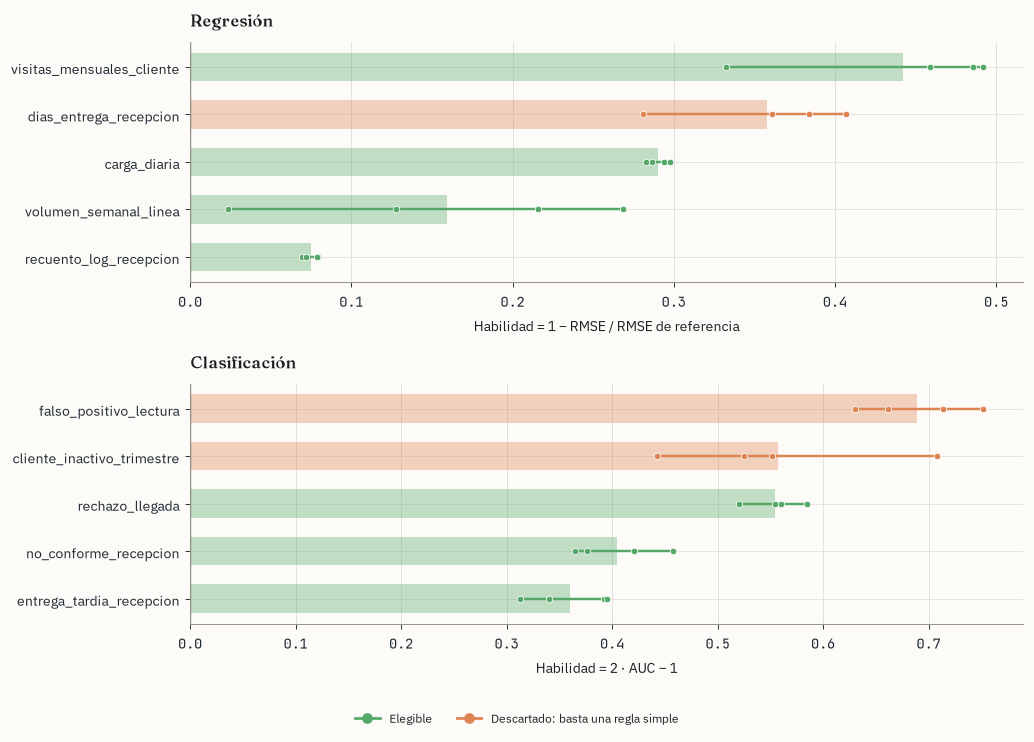

In [4]:
cribado.prueba_rapida(c).mostrar()

## 4. ¿Basta una regla simple?

Un modelo solo se justifica si combina información: en cada bloque se entrena un árbol que ve una
sola variable (la que más aporta) y, si su habilidad llega al umbral frente al mejor modelo rápido,
la recomendación es una regla operativa y no un modelo.

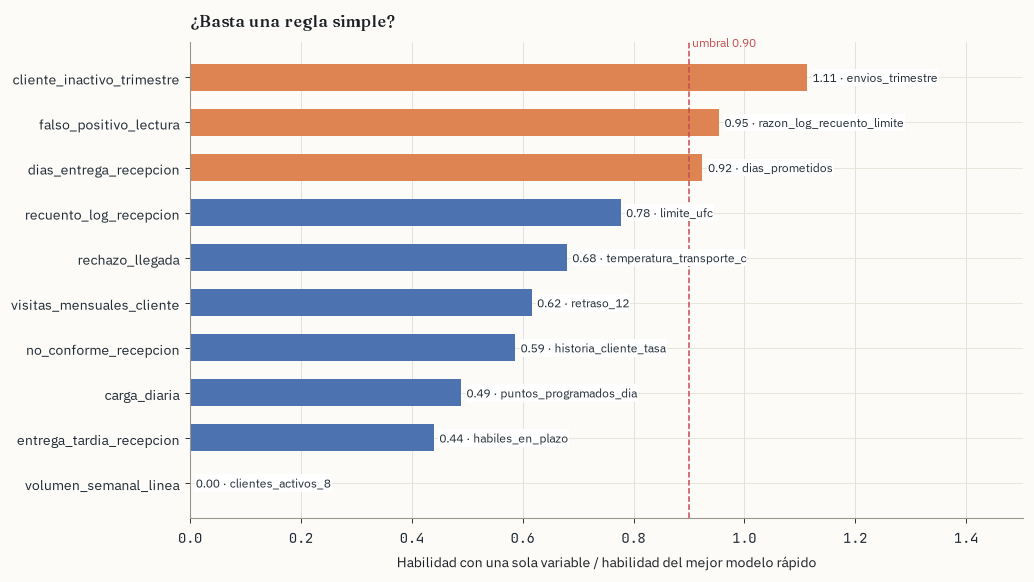

In [5]:
cribado.regla_simple(c).mostrar()

## 5. Candidatos de agrupamiento

Sin línea base que superar, la prueba pregunta si hay tendencia a formar grupos (Hopkins: cerca de
0.5 sin estructura, hacia 1 con grupos) y qué tan separados quedan los grupos de K-means (silueta).

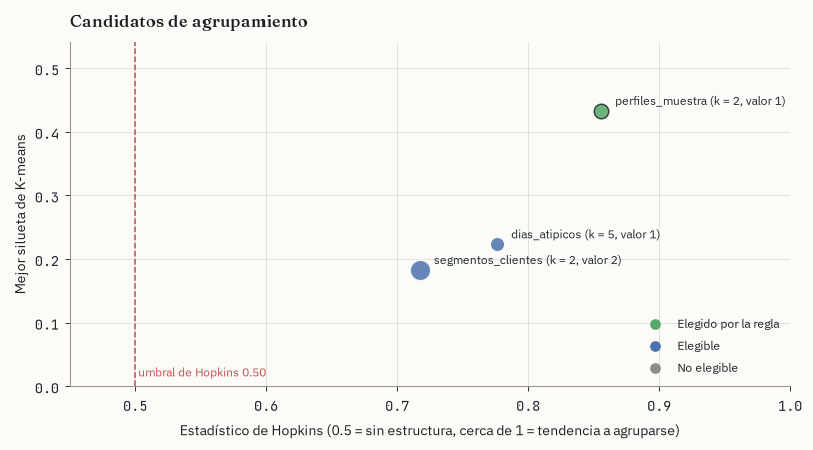

In [6]:
cribado.candidatos_agrupamiento(c).mostrar()

## 6. Selección

El embudo resume cuántos candidatos quedan en cada paso; las comparaciones muestran los mejores
puntajes de cada tipo, incluidos los no elegibles, para que se vea qué se dejó de lado y por qué.

In [7]:
cribado.seleccion(c).mostrar()

## 7. Consecuencias para las etapas siguientes

La selección no se toca después: las etapas 04 a 06 leen `artefactos/03_cribado.json`. La única
excepción, declarada aquí, es un análisis de agrupamiento complementario sobre los clientes.

In [8]:
cribado.consecuencias(c).mostrar()

In [9]:
cribado.terminar(c)

← Anterior: [02 · Exploración](02_exploracion.ipynb) &nbsp;·&nbsp; [Notebook completo](Proyecto_Final.ipynb) &nbsp;·&nbsp; Siguiente: [04 · Regresión](04_regresion.ipynb) →